# Final Análisis Estadístico de Datos

**Nombre**:  Constanza Bencharski

**Cuatrimestre**:  2do cuatrimestre del 2024

Un experimento consiste en contar el número de partículas detectadas por un detector ($k$) sobre un total de partículas incidentes ($n$) para medir la eficiencia del detector. El experimento se repite para distintas energías de la partículas incidentes ($E$). Buscamos ajustar un modelo de la eficiencia $\varepsilon$ en función de la energía en base a los datos medidos. La siguiente tabla muestra los resultados del experimento.  

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import likefit

energy = np.arange(start=0.05, stop=1.05, step=0.05)
ntrials = 30
total_particles = np.full(energy.shape, ntrials)
observed_particles = np.array([0, 0, 0, 3, 3, 2, 8, 5, 4, 11, 18, 15, 19, 20, 26, 24, 26, 29, 30, 30])
data = pd.DataFrame(data = {'Energy': energy, 'Total': total_particles, 'Observed': observed_particles})
data

,Energy,Total,Observed
0,0.05,30,0
1,0.10,30,0
2,0.15,30,0
3,0.20,30,3
4,0.25,30,3
5,0.30,30,2
6,0.35,30,8
7,0.40,30,5
8,0.45,30,4
9,0.50,30,11


### Distribución Binomial

La probabilidad de observar $k$ partículas detectadas dado $n$ y $\varepsilon$ está dada por la función de probabilidad de la distribución binomial:


$P(k | n, \varepsilon) = \binom{n}{k} \varepsilon^k (1-\varepsilon)^{n-k}$


Donde:

- $n$ es el número total de partículas incidentes,
- $k$ es el número de partículas detectadas,
- $\varepsilon$ es la probabilidad de detección (eficiencia del detector)

**1**. Calcular el estimador de la eficiencia del detector ($\hat\varepsilon$) para cada energía

### Estimador de máxima verosimilitud (MLE) para una Binomial:

Para encontrar el estimador de máxima verosimilitud $\hat{\varepsilon}$ partimos de la función de verosimilitud (likelihood) para una distribución binomial:  

$L(\varepsilon) = \binom{n}{k} \varepsilon^{k} \left(1 - \varepsilon\right)^{n - k}$

En lugar de trabajar directamente con la verosimilitud, usamos el logaritmo de la verosimilitud, que convierte el producto en una suma y es más manejable:

$\text{ln}(L(\varepsilon)) = \text{ln}\binom{n}{k} + k \, \text{ln}(\varepsilon) \, (n-k) \, \text{ln}(1-\varepsilon) $

##### Maximización:

$\left. \frac{d \ln(L(\varepsilon))}{d\varepsilon} \right|_{\varepsilon = \hat{\varepsilon}} = 0$

$\frac{k}{\hat{\varepsilon}} + \frac{(n-k)}{1-\hat{\varepsilon}} = 0$

$\boxed{\hat{\varepsilon} = \frac{k}{n}}$

In [ ]:
# Calculo del estimador epsilon para cada energia

epsilon_hat = observed_particles/total_particles
epsilon_hat

array([0.        , 0.        , 0.        , 0.1       , 0.1       ,
       0.06666667, 0.26666667, 0.16666667, 0.13333333, 0.36666667,
       0.6       , 0.5       , 0.63333333, 0.66666667, 0.86666667,
       0.8       , 0.86666667, 0.96666667, 1.        , 1.        ])

**2**. Graficar el estimador de la eficiencia ($\hat\varepsilon$) en función de la energía

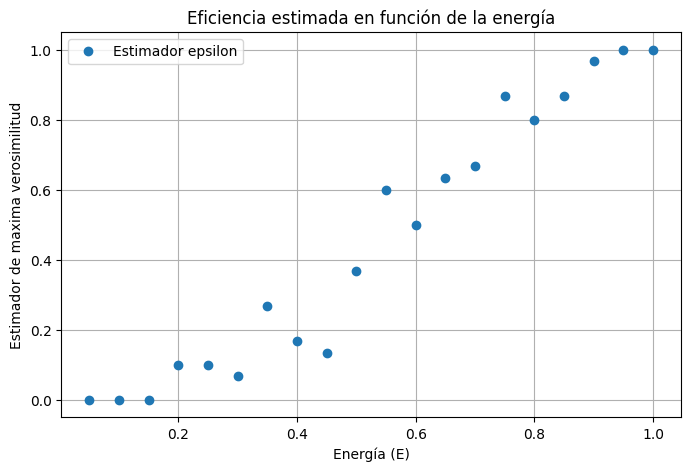

In [ ]:
# Grafica MLE vs E
plt.figure(figsize=(8, 5))
plt.plot(energy, epsilon_hat, 'o', label='Estimador epsilon')
plt.xlabel("Energía (E)")
plt.ylabel("Estimador de maxima verosimilitud")
plt.title("Eficiencia estimada en función de la energía")
plt.grid(True)
plt.legend()
plt.show()

**3**. Escribir el código para el modelo del ajuste  
El modelo de la eficiencia en función de la energía es la función sigmoide,
\begin{equation}
\varepsilon(E;a,b)=\frac{1}{1+\exp(-(E-a)/b)},
\end{equation}
con $a$ y $b$ los parámetros del ajuste.

In [ ]:
from scipy.special import expit

# Modelo con la función sigmoide usando expit

def model(E, par):
    a = par[0]
    b = par[1]
    return expit((E - a) / b)


**4**. Ajustar los datos con el modelo de la eficiencia con una función de costo Binomial

### Función de costo Binomial:

Si los datos siguen una distribución binomial, la función de verosimilitud (likelihood) está dada por:

$L(\theta) = \prod_{i} \binom{n_i}{k_i} \varepsilon(x_i; \theta)^{k_i} \left(1 - \varepsilon(x_i; \theta)\right)^{n_i - k_i}$

Donde $\theta = (a,b)$ es el vector de los parámetros.

La verosimilitud máxima ($L(\hat{\varepsilon})$) está dada por:

$ L_{max} = L(\hat{\epsilon}) = \prod_{i} \binom{n_i}{k_i} (\frac{k_i}{n_i})^{k_i} \left(1 - (\frac{k_i}{n_i})\right)^{n_i - k_i}$

Logaritmo de las verosimilitudes:

1.  $\text{ln}(L(\theta)) = \text{ln}(\binom{n}{k}) + k \, \text{ln}(\varepsilon(x, \theta)) + (n-k)\text{ln}(1 - \varepsilon(x, \theta))$
2.  $\text{ln}(L(\hat{\varepsilon})) = \text{ln}(\binom{n}{k}) + k \, \text{ln}(\frac{k}{n}) + (n-k)\text{ln}(1 - \frac{k}{n})$

Por último, la función de costo binomial estará dada por:

$J(\theta) = 2 \, \text{ln}(\frac{L(\theta)}{L(\hat{\varepsilon})}) = 2 \, \text{ln}(L(\theta)) - 2 \, \text{ln}(L(\hat{\varepsilon})) $

La resta de estas dos funciones permite deshacernos de constantes irrelevantes que no intervienen en el proceso de minimización.


El, objetivo es, entonces, minimizar la función de costo para obtener los parámetros del modelo con el que se ajustarán los datos.

Para ajustar los datos al modelo de la eficiencia utilizando una función de costo binomial, se empleará la librería *likefit* (<3). Esta herramienta, que apreciamos profundamente, calcula la función de costo correspondiente a una distribución binomial. Para determinar los estimadores, minimiza dicha función mediante métodos de optimización como el descenso por gradiente u otros, los cuales requieren una semilla inicial. Además, *likefit* proporciona los errores y la matriz de correlación de los parámetros ajustados, así como la bondad del ajuste y el p-value.  

In [ ]:
help(likefit.Binomial)

Help on class Binomial in module likefit:

class Binomial(LikelihoodFitter)
 |  Binomial(x, ntrials, nsuccess, model)
 |
 |  Binomial fitter based on the LikelihoodFitter base class.
 |
 |  Parameters
 |  ----------
 |  ntrials : array_like
 |      The number of trials data.
 |  nsuccess : array_like
 |      The number of successful trials data.
 |  model : callable
 |      The Binomial model function to fit the data.
 |
 |  Attributes
 |  ----------
 |  ntrials : array_like
 |      The number of trials data.
 |  nsuccess : array_like
 |      The number of successful trials data.
 |  model : callable
 |      The model function to fit the data.
 |
 |  Method resolution order:
 |      Binomial
 |      LikelihoodFitter
 |      abc.ABC
 |      builtins.object
 |
 |  Methods defined here:
 |
 |  __init__(self, x, ntrials, nsuccess, model)
 |      Initialize the Binomial fitter instance.
 |
 |      Parameters
 |      ----------
 |      ntrials : array_like
 |          The number of trials da

In [ ]:
fitter = likefit.Binomial(energy, ntrials, observed_particles, model)

In [ ]:
initial_parameters = np.array([1,1])   # semillas para iniciar la optimización
fit_result = fitter.fit(initial_parameters)
fitter.print_results()

Fit summary
Estimators: [0.57149282 0.12099439]
Errors: [0.01431932 0.0091239 ]
Covariance matrix: [[2.05042858e-04 2.74771307e-06]
 [2.74771307e-06 8.32456252e-05]]
Correlation matrix: [[1.         0.02103141]
 [0.02103141 1.        ]]
Chi square: 24.01055559005024
Degrees of freedom: 18
Pvalue: 0.15468226740415705


**5**. Reportar los resultados para los parámetros $a$ y $b$ incluyendo los errores correspondientes

In [ ]:
# Resultados para los parámetros a y b
estimators = fitter.get_estimators()
errors = fitter.get_errors()
print(f"a: {estimators[0]:.3f} ± {errors[0]:.3f}")
print(f"b: {estimators[1]:.3f} ± {errors[1]:.3f}")

a: 0.571 ± 0.014
b: 0.121 ± 0.009


**6**. Reportar la correlación entre los estimadores de los parámetros $a$ y $b$

In [ ]:
# Matriz de correlación de los parámetros a y b
corr = fitter.get_correlation_matrix()
corr

array([[1.        , 0.02103141],
       [0.02103141, 1.        ]])

Se observa que los parámetros a y b están poco correlacionados. Esto es una buena señal debido a que una alta correlación entre los parámetros puede significar redundancias en el modelo.

**7**. Graficar la región de confianza $1\sigma$ de los parámetros $a$ y $b$

In [ ]:
help(fitter.plot_confidence_regions)

Help on method plot_confidence_regions in module likefit:

plot_confidence_regions(parx_index=0, pary_index=1, nsigma=2, ax=None) method of likefit.Binomial instance
    Plot the confidence regions for a pair of parameters.

    Parameters
    ----------
    parx_index : int
        Index of the x-axis parameter. The first parameter is plotted by default.
    pary_index : int
        Index of the y-axis parameter. The second parameter is plotted by default.
    nsigma : int, optional
        Number of sigma confidence levels to plot.
    ax : matplotlib.axis.Axis, optional
        Axis to make the plot.

    Returns
    -------
    None



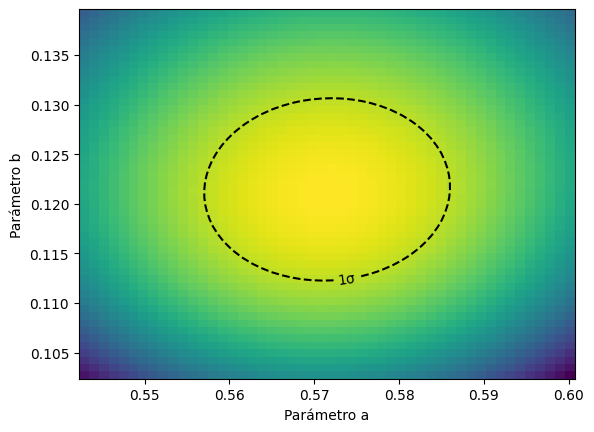

In [ ]:
# Region de confianza 1sigma
fig, ax = plt.subplots()
ax.set_xlabel("Parámetro a")
ax.set_ylabel("Parámetro b")
fitter.plot_confidence_regions(0, 1, 1, ax=ax)

**8**. Calcular el $\chi^2$ del ajuste y su p-valor. Decidir si el modelo es consistente con los datos.

### Bondad del ajuste (goodness of fit)

La bondad del ajuste es una medida de qué tan bien un modelo ajustado representa los datos experimentales. Evalúa si las diferencias entre los valores observados y los valores predichos por el modelo (residuos) son pequeñas y compatibles con las incertidumbres de los datos.



In [ ]:
chi_square = fitter.get_chi_square()
print(f"chi^2 = {chi_square:.3f}")

chi^2 = 24.011


In [ ]:
p_value = fitter.get_pvalue()
print(f"p_value = {p_value:.3f}")

p_value = 0.155


### P-value

Un número pequeño de p-value indica que el ajuste no representa bien a los datos, y un p-value cercano a 1 podría ser una señal de overffiting. Sin embargo, el valor obtenido para este problema sugiere que el ajuste es aceptable, es decir, que el modelo para la eficiencia del detector utilizado parece ser una buena representación de los datos experimentales.



**9**. Graficar los datos y el ajuste incluyendo la banda de error del ajuste

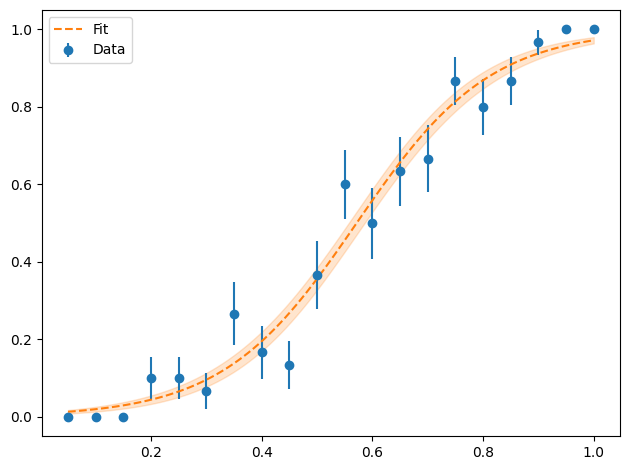

In [ ]:
# Grafico de los datos, ajuste y banda de error

fig, ax = plt.subplots()
fitter.plot_fit(xlabel="Energia", ylabel="Eficiencia del detector", ax=ax)

En el gráfico se observa que el modelo ajustado sigue adecuadamente la tendencia general de los datos